[15:39:13] INFO     | ##############################################################################


INFO:unemployment:##############################################################################


[15:39:13] INFO     |                    UNEMPLOYMENT ANALYSIS - CodeAlpha Task 2                   


INFO:unemployment:                   UNEMPLOYMENT ANALYSIS - CodeAlpha Task 2                   


[15:39:13] INFO     | ##############################################################################


...

INFO:unemployment:==============================================================================


[15:39:13] INFO     |                             SEASONAL DECOMPOSITION                            


INFO:unemployment:                            SEASONAL DECOMPOSITION                            


[15:39:13] INFO     | ==============================================================================


INFO:unemployment:==============================================================================


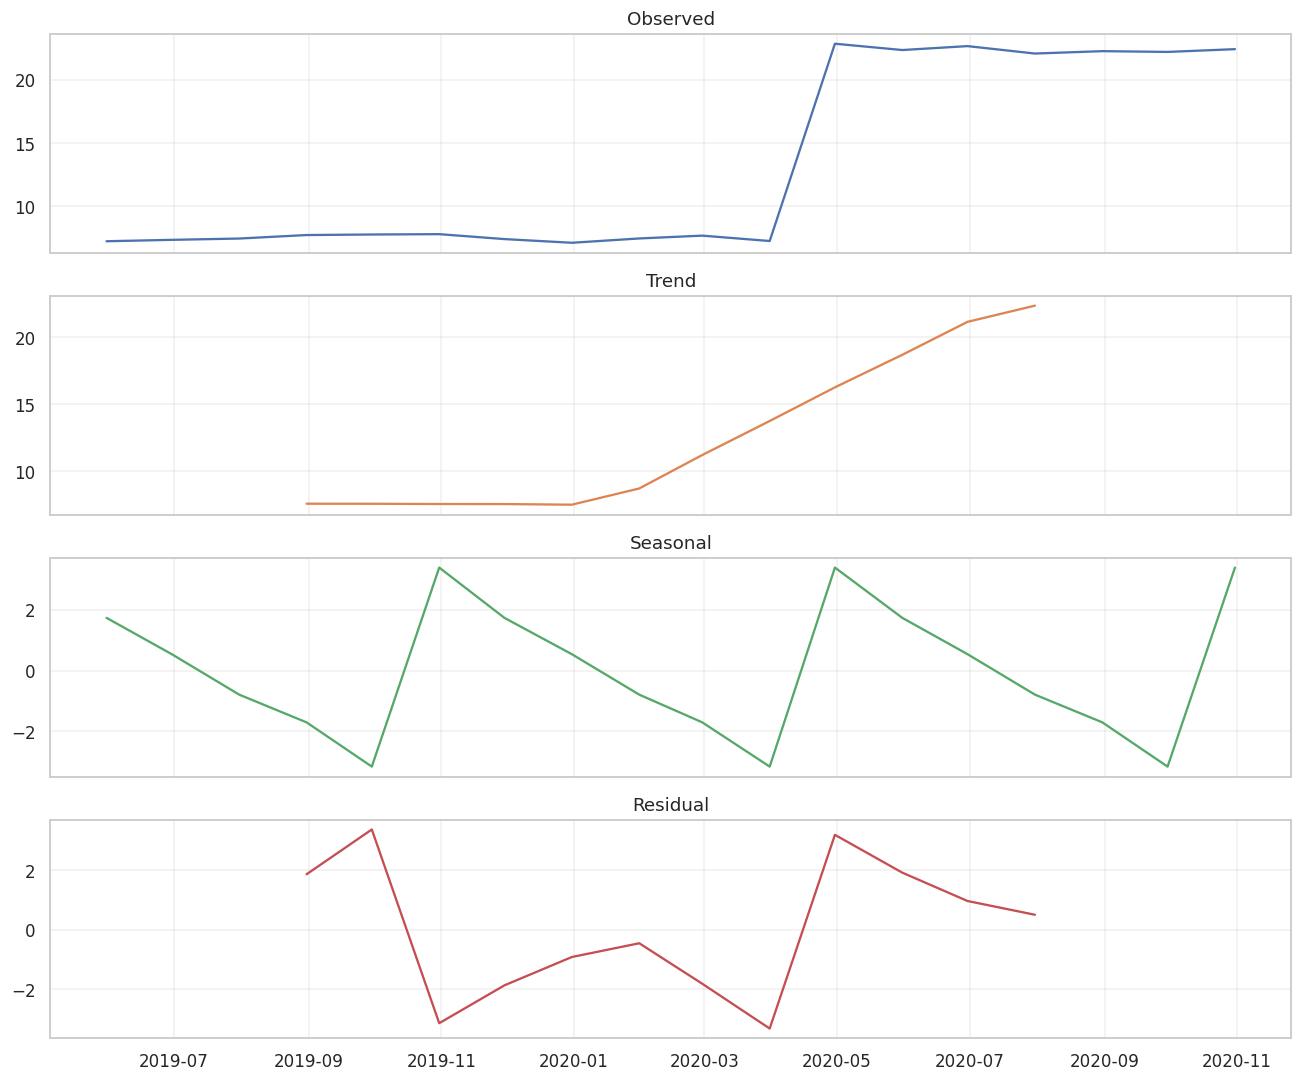

[15:39:15] INFO     | ==============================================================================


INFO:unemployment:==============================================================================


[15:39:15] INFO     |                                STATE CLUSTERING                               


INFO:unemployment:                               STATE CLUSTERING                               


[15:39:15] INFO     | ==============================================================================


...

INFO:unemployment:==============================================================================


[15:39:15] INFO     | Outliers: 17 / 324


INFO:unemployment:Outliers: 17 / 324


[15:39:16] INFO     |   |- saved -> artifacts_unemployment/01_trend_over_time.png


INFO:unemployment:  |- saved -> artifacts_unemployment/01_trend_over_time.png


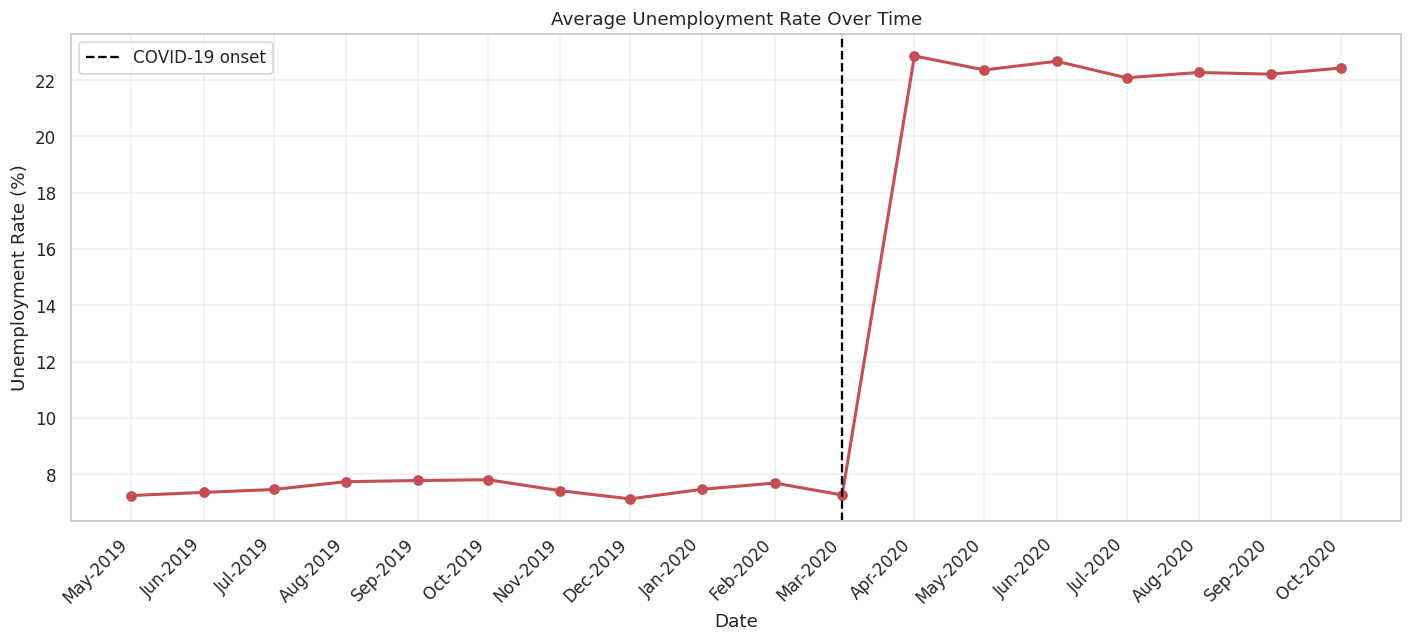

[15:39:16] INFO     |   |- saved -> artifacts_unemployment/02_state_ranking.png


INFO:unemployment:  |- saved -> artifacts_unemployment/02_state_ranking.png


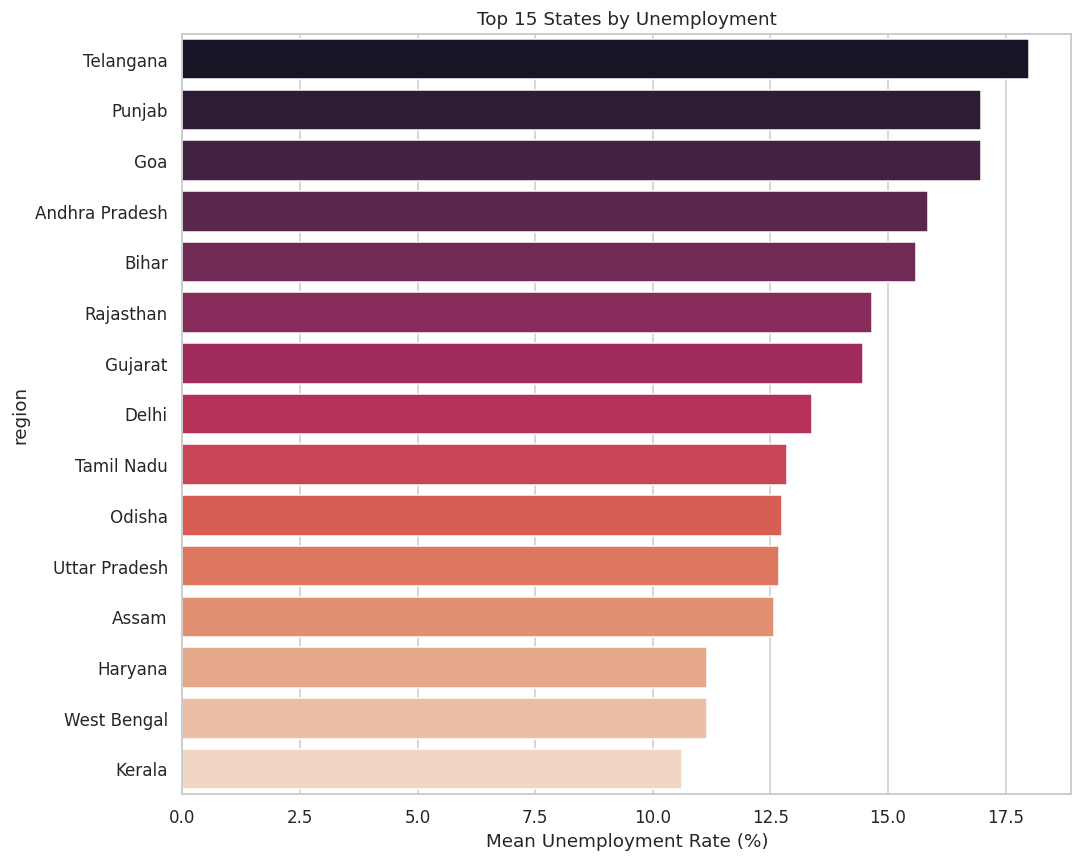

[15:39:17] INFO     |   |- saved -> artifacts_unemployment/03_covid_comparison.png


INFO:unemployment:  |- saved -> artifacts_unemployment/03_covid_comparison.png


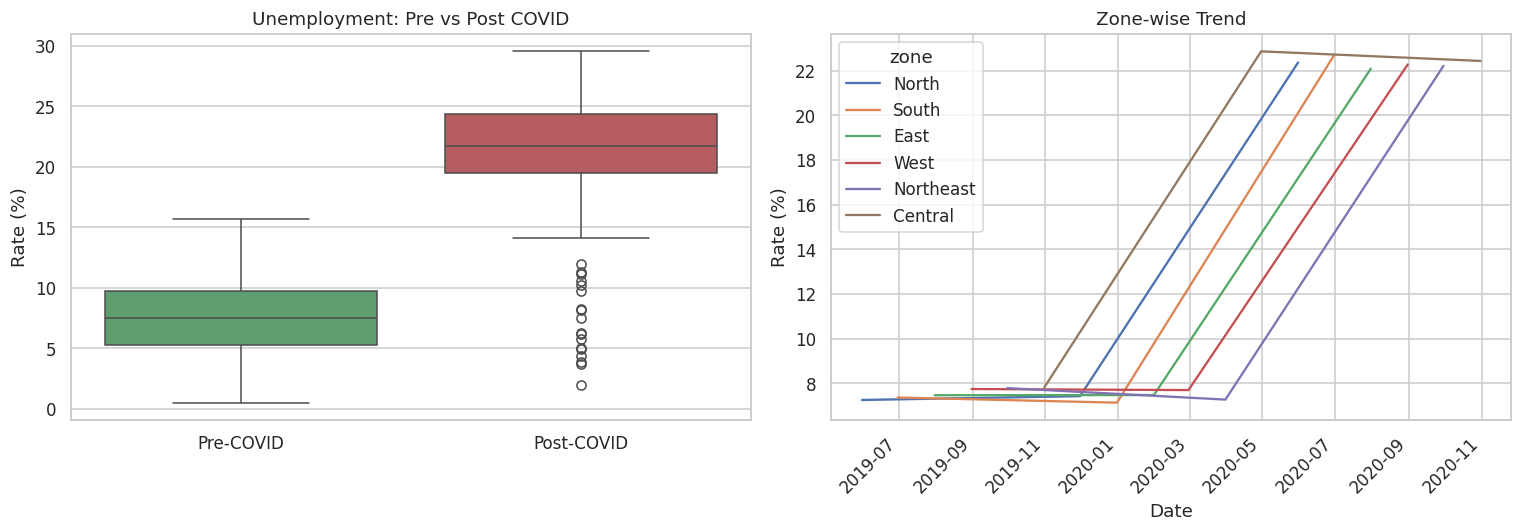

[15:39:18] INFO     |   |- saved -> artifacts_unemployment/04_heatmap_state_month.png


INFO:unemployment:  |- saved -> artifacts_unemployment/04_heatmap_state_month.png


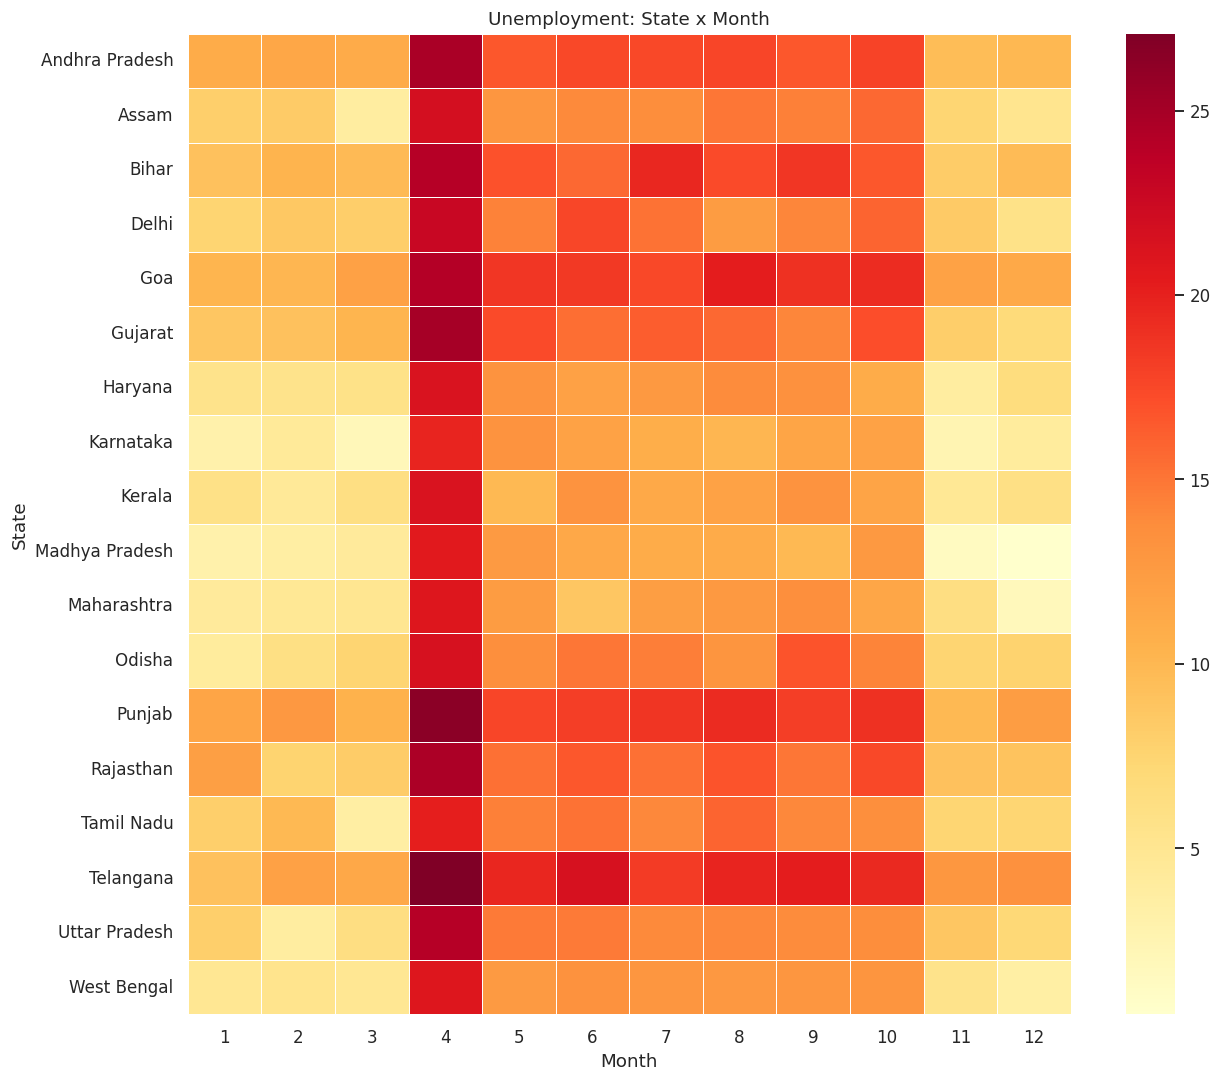

[15:39:18] INFO     |   |- saved -> artifacts_unemployment/05_cluster_scatter.png


INFO:unemployment:  |- saved -> artifacts_unemployment/05_cluster_scatter.png


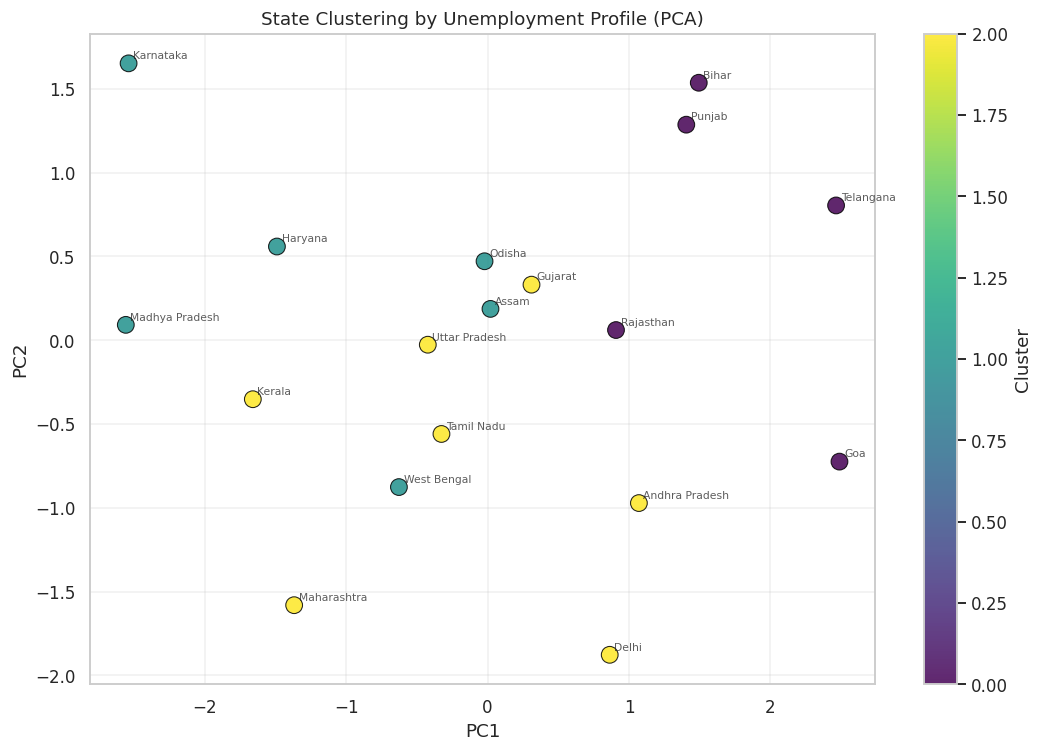

[15:39:19] INFO     |   |- saved -> artifacts_unemployment/06_outlier_scatter.png


INFO:unemployment:  |- saved -> artifacts_unemployment/06_outlier_scatter.png


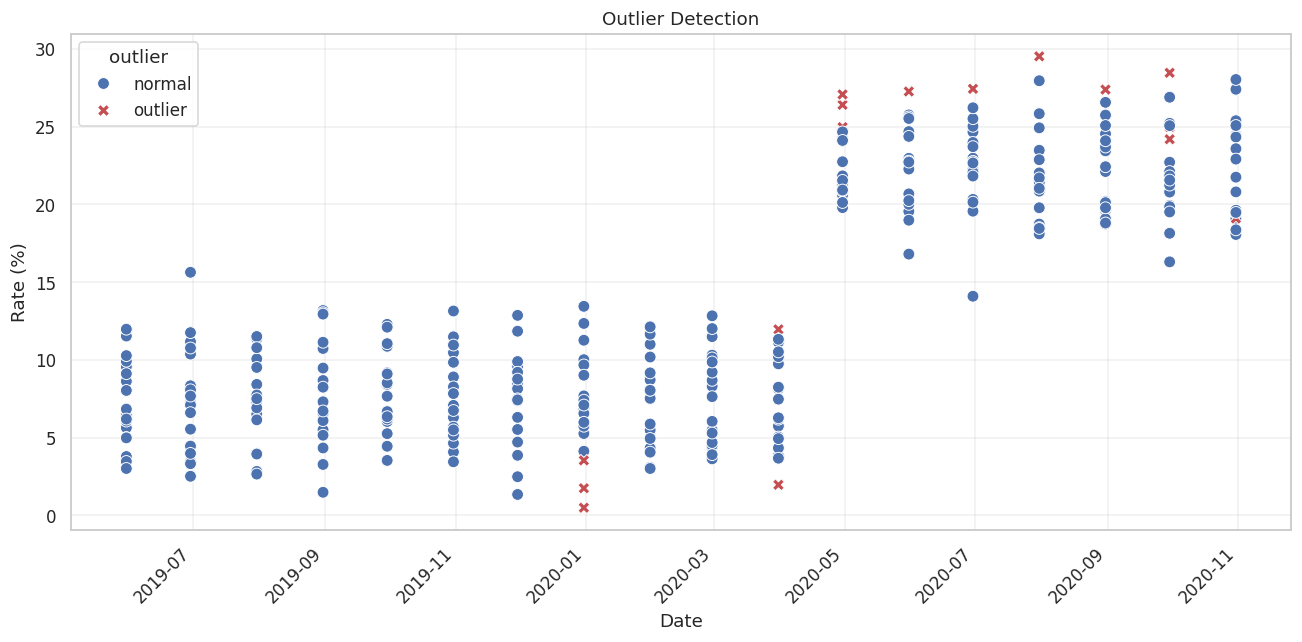

[15:39:19] INFO     |   |- saved -> artifacts_unemployment/08_correlation.png


INFO:unemployment:  |- saved -> artifacts_unemployment/08_correlation.png


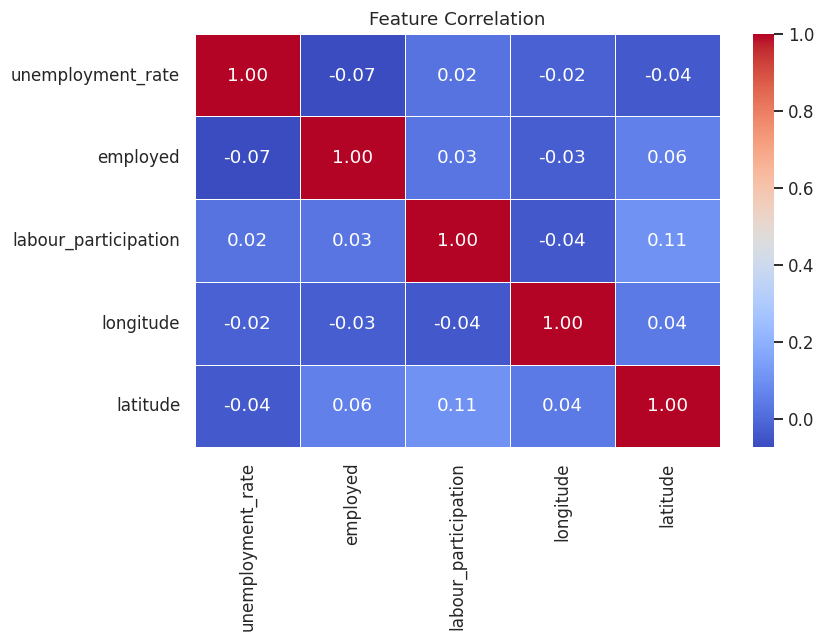

[15:39:20] INFO     |   |- saved -> artifacts_unemployment/09_zone_distribution.png


INFO:unemployment:  |- saved -> artifacts_unemployment/09_zone_distribution.png


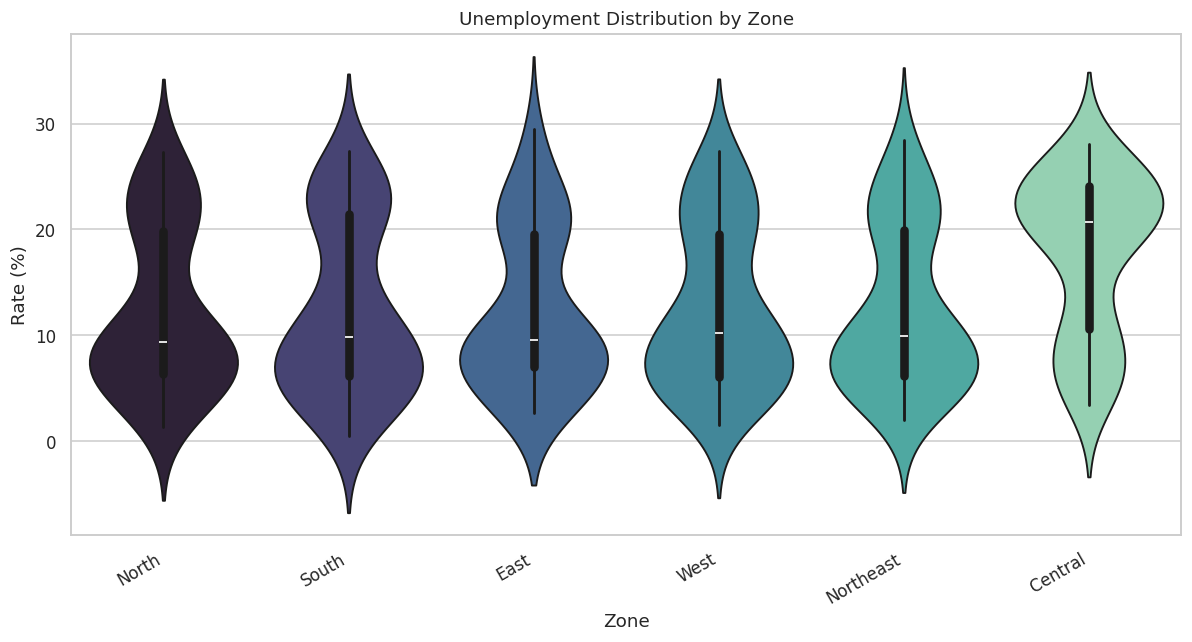

[15:39:20] INFO     | ==============================================================================


INFO:unemployment:==============================================================================


[15:39:20] INFO     |                                  KEY INSIGHTS                                 


INFO:unemployment:                                 KEY INSIGHTS                                 


[15:39:20] INFO     | ==============================================================================


...

INFO:unemployment:##############################################################################


[15:39:20] INFO     |                               PIPELINE COMPLETE                               


INFO:unemployment:                              PIPELINE COMPLETE                               


[15:39:20] INFO     | ##############################################################################


INFO:unemployment:##############################################################################


In [ ]:
import logging
import sys
import warnings
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.bbox"] = "tight"


@dataclass
class Config:
    random_state: int = 42
    output_dir: Path = Path("artifacts_unemployment")
    fig_dpi: int = 110
    palette: str = "viridis"


CFG = Config()
CFG.output_dir.mkdir(parents=True, exist_ok=True)


def setup_logger(name="unemployment"):
    logger = logging.getLogger(name)
    if logger.handlers:
        return logger
    logger.setLevel(logging.INFO)
    fmt = logging.Formatter("[%(asctime)s] %(levelname)-8s | %(message)s",
                            datefmt="%H:%M:%S")
    sh = logging.StreamHandler(sys.stdout)
    sh.setFormatter(fmt)
    logger.addHandler(sh)
    return logger


LOG = setup_logger()


def banner(title, char="=", width=78):
    LOG.info(char * width)
    LOG.info(title.center(width))
    LOG.info(char * width)


class UnemploymentDataLoader:
    def __init__(self, cfg):
        self.cfg = cfg

    def load(self):
        p1 = Path("Unemployment in India.csv")
        p2 = Path("Unemployment_Rate_upto_11_2020.csv")
        if not p1.exists() and not p2.exists():
            LOG.warning("CSVs not found - using synthetic fallback")
            df = self._synthetic()
            return df, df
        frames = []
        for p in [p1, p2]:
            if p.exists():
                df = pd.read_csv(p)
                df.columns = [c.strip() for c in df.columns]
                frames.append(df)
                LOG.info("Loaded %s -> %s", p.name, df.shape)
        if not frames:
            df = self._synthetic()
            return df, df
        return frames[0], (frames[1] if len(frames) > 1 else frames[0])

    def _synthetic(self):
        rng = np.random.default_rng(CFG.random_state)
        states = ["Andhra Pradesh", "Assam", "Bihar", "Delhi", "Goa",
                  "Gujarat", "Haryana", "Karnataka", "Kerala",
                  "Madhya Pradesh", "Maharashtra", "Odisha", "Punjab",
                  "Rajasthan", "Tamil Nadu", "Telangana", "Uttar Pradesh",
                  "West Bengal"]
        zones = ["North", "South", "East", "West", "Northeast", "Central"]
        dates = pd.date_range("2019-05-31", "2020-10-31", freq="ME")
        rows = []
        for state in states:
            base = rng.uniform(4, 12)
            for i, d in enumerate(dates):
                covid = 15 if d >= pd.Timestamp("2020-04-30") else 0
                val = max(0.5, base + covid + rng.normal(0, 1.5))
                rows.append({
                    "Region": state,
                    "Date": d.strftime("%d-%m-%Y"),
                    "Frequency": "Monthly",
                    "Estimated Unemployment Rate (%)": round(val, 2),
                    "Estimated Employed": int(rng.uniform(1e6, 5e7)),
                    "Estimated Labour Participation Rate (%)":
                        round(rng.uniform(35, 55), 2),
                    "Region.1": zones[i % len(zones)],
                    "longitude": rng.uniform(68, 97),
                    "latitude": rng.uniform(8, 37),
                })
        return pd.DataFrame(rows)


class DataCleaner:
    def __init__(self, cfg):
        self.cfg = cfg

    def clean(self, df):
        df = df.copy()
        df.columns = [c.strip() for c in df.columns]
        rename = {
            "Region": "region",
            "Date": "date",
            "Frequency": "frequency",
            "Estimated Unemployment Rate (%)": "unemployment_rate",
            "Estimated Employed": "employed",
            "Estimated Labour Participation Rate (%)": "labour_participation",
            "Region.1": "zone",
            "longitude": "longitude",
            "latitude": "latitude",
        }
        df = df.rename(columns={k: v for k, v in rename.items()
                                if k in df.columns})
        df["date"] = pd.to_datetime(df["date"], dayfirst=True, errors="coerce")
        for c in ["unemployment_rate", "employed", "labour_participation",
                  "longitude", "latitude"]:
            if c in df.columns:
                df[c] = pd.to_numeric(df[c], errors="coerce")
        df = df.dropna(subset=["date", "unemployment_rate"]).reset_index(drop=True)
        df["year"] = df["date"].dt.year
        df["month"] = df["date"].dt.month
        df["is_covid"] = (df["date"] >= "2020-03-01").astype(int)
        LOG.info("Cleaned -> shape=%s | %s to %s", df.shape,
                 df["date"].min().date(), df["date"].max().date())
        return df


class UnemploymentAnalyzer:
    def __init__(self, cfg):
        self.cfg = cfg

    def describe(self, df):
        banner("STATISTICAL OVERVIEW")
        cols = ["unemployment_rate", "employed", "labour_participation"]
        cols = [c for c in cols if c in df.columns]
        desc = df[cols].describe().T
        LOG.info("\n%s", desc.round(3).to_string())

    def covid_impact(self, df):
        banner("COVID-19 IMPACT")
        pre = df[df["is_covid"] == 0]["unemployment_rate"]
        post = df[df["is_covid"] == 1]["unemployment_rate"]
        t, p = stats.ttest_ind(pre, post, equal_var=False)
        uplift = (post.mean() - pre.mean()) / pre.mean() * 100
        LOG.info("Pre-COVID mean : %.2f%%", pre.mean())
        LOG.info("Post-COVID mean: %.2f%%", post.mean())
        LOG.info("Uplift         : %.2f%%", uplift)
        LOG.info("t=%.4f | p=%.4g", t, p)
        monthly = df.groupby(df["date"].dt.to_period("M"))[
            "unemployment_rate"].mean().reset_index()
        monthly.columns = ["month", "unemployment_rate"]
        monthly["month"] = monthly["month"].dt.to_timestamp()
        return monthly

    def seasonal_decomposition(self, df):
        banner("SEASONAL DECOMPOSITION")
        series = df.groupby("date")["unemployment_rate"].mean().sort_index()
        if len(series) < 12:
            LOG.warning("Too few periods for decomposition")
            return series
        try:
            decomp = seasonal_decompose(series, model="additive", period=6)
        except Exception as exc:
            LOG.warning("Decomposition failed: %s", exc)
            return series
        fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)
        axes[0].plot(series.index, series.values, color="#4C72B0")
        axes[0].set_title("Observed")
        axes[1].plot(series.index, decomp.trend, color="#DD8452")
        axes[1].set_title("Trend")
        axes[2].plot(series.index, decomp.seasonal, color="#55A868")
        axes[2].set_title("Seasonal")
        axes[3].plot(series.index, decomp.resid, color="#C44E52")
        axes[3].set_title("Residual")
        for a in axes:
            a.grid(alpha=0.3)
        plt.tight_layout()
        fig.savefig(CFG.output_dir / "07_seasonal_decomposition.png",
                    dpi=CFG.fig_dpi, bbox_inches="tight")
        plt.show()
        return series

    def cluster_states(self, df, n_clusters=3):
        banner("STATE CLUSTERING")
        feat = df.groupby("region").agg(
            mean_unemp=("unemployment_rate", "mean"),
            std_unemp=("unemployment_rate", "std"),
            max_unemp=("unemployment_rate", "max"),
            mean_labour=("labour_participation", "mean"),
        ).dropna()
        X = StandardScaler().fit_transform(feat)
        km = KMeans(n_clusters=n_clusters, n_init=10,
                    random_state=self.cfg.random_state)
        feat["cluster"] = km.fit_predict(X)
        pca = PCA(n_components=2, random_state=self.cfg.random_state)
        coords = pca.fit_transform(X)
        feat["pc1"], feat["pc2"] = coords[:, 0], coords[:, 1]
        return feat

    def detect_outliers(self, df):
        banner("OUTLIER DETECTION")
        cols = ["unemployment_rate", "employed", "labour_participation"]
        cols = [c for c in cols if c in df.columns]
        sub = df[cols].dropna()
        iso = IsolationForest(contamination=0.05,
                              random_state=self.cfg.random_state)
        df = df.loc[sub.index].copy()
        df["outlier"] = iso.fit_predict(sub)
        df["outlier"] = df["outlier"].map({1: "normal", -1: "outlier"})
        LOG.info("Outliers: %d / %d",
                 (df["outlier"] == "outlier").sum(), len(df))
        return df


class UnemploymentVisualizer:
    def __init__(self, cfg):
        self.cfg = cfg
        self.out = cfg.output_dir

    def _save(self, fig, name):
        path = self.out / name
        fig.savefig(path, dpi=self.cfg.fig_dpi, bbox_inches="tight")
        LOG.info("  |- saved -> %s", path)

    def trend_over_time(self, monthly):
        fig, ax = plt.subplots(figsize=(13, 6))
        ax.plot(monthly["month"], monthly["unemployment_rate"],
                marker="o", lw=2, color="#C44E52")
        covid_start = pd.Timestamp("2020-03-01")
        if monthly["month"].min() <= covid_start <= monthly["month"].max():
            ax.axvline(covid_start, color="black", ls="--", lw=1.5,
                       label="COVID-19 onset")
        ax.set(xlabel="Date", ylabel="Unemployment Rate (%)",
               title="Average Unemployment Rate Over Time")
        ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%Y"))
        plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
        ax.legend()
        ax.grid(alpha=0.3)
        plt.tight_layout()
        self._save(fig, "01_trend_over_time.png")
        plt.show()

    def state_ranking(self, df, top_n=15):
        top = df.groupby("region")["unemployment_rate"].mean().sort_values(
            ascending=False).head(top_n)
        fig, ax = plt.subplots(figsize=(10, 8))
        sns.barplot(x=top.values, y=top.index, palette="rocket", ax=ax)
        ax.set(xlabel="Mean Unemployment Rate (%)",
               title=f"Top {top_n} States by Unemployment")
        plt.tight_layout()
        self._save(fig, "02_state_ranking.png")
        plt.show()

    def covid_comparison(self, df):
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        sns.boxplot(data=df, x="is_covid", y="unemployment_rate",
                    palette=["#55A868", "#C44E52"], ax=axes[0])
        axes[0].set_xticklabels(["Pre-COVID", "Post-COVID"])
        axes[0].set(title="Unemployment: Pre vs Post COVID",
                    xlabel="", ylabel="Rate (%)")
        if "zone" in df.columns:
            mz = df.groupby(["date", "zone"])[
                "unemployment_rate"].mean().reset_index()
            sns.lineplot(data=mz, x="date", y="unemployment_rate",
                         hue="zone", ax=axes[1])
            axes[1].set(title="Zone-wise Trend",
                        xlabel="Date", ylabel="Rate (%)")
            plt.setp(axes[1].get_xticklabels(), rotation=45, ha="right")
        plt.tight_layout()
        self._save(fig, "03_covid_comparison.png")
        plt.show()

    def heatmap_state_month(self, df):
        pivot = df.pivot_table(index="region", columns="month",
                               values="unemployment_rate", aggfunc="mean")
        fig, ax = plt.subplots(figsize=(12, 10))
        sns.heatmap(pivot, cmap="YlOrRd", linewidths=0.5, ax=ax)
        ax.set(title="Unemployment: State x Month",
               xlabel="Month", ylabel="State")
        plt.tight_layout()
        self._save(fig, "04_heatmap_state_month.png")
        plt.show()

    def cluster_scatter(self, feat):
        fig, ax = plt.subplots(figsize=(10, 7))
        sc = ax.scatter(feat["pc1"], feat["pc2"], c=feat["cluster"],
                        cmap="viridis", s=120, alpha=0.85,
                        edgecolors="black", linewidths=0.7)
        for state, row in feat.iterrows():
            ax.annotate(state, (row["pc1"], row["pc2"]), fontsize=7,
                        alpha=0.75, xytext=(3, 3),
                        textcoords="offset points")
        ax.set(xlabel="PC1", ylabel="PC2",
               title="State Clustering by Unemployment Profile (PCA)")
        plt.colorbar(sc, ax=ax, label="Cluster")
        ax.grid(alpha=0.3)
        plt.tight_layout()
        self._save(fig, "05_cluster_scatter.png")
        plt.show()

    def outlier_scatter(self, df):
        fig, ax = plt.subplots(figsize=(12, 6))
        sns.scatterplot(data=df, x="date", y="unemployment_rate",
                        hue="outlier", style="outlier", s=60, ax=ax,
                        palette={"normal": "#4C72B0",
                                 "outlier": "#C44E52"})
        ax.set(title="Outlier Detection",
               xlabel="Date", ylabel="Rate (%)")
        plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
        ax.grid(alpha=0.3)
        plt.tight_layout()
        self._save(fig, "06_outlier_scatter.png")
        plt.show()

    def correlation(self, df):
        cols = [c for c in ["unemployment_rate", "employed",
                            "labour_participation", "longitude", "latitude"]
                if c in df.columns]
        fig, ax = plt.subplots(figsize=(8, 6))
        sns.heatmap(df[cols].corr(), annot=True, fmt=".2f",
                    cmap="coolwarm", linewidths=0.5, ax=ax)
        ax.set_title("Feature Correlation")
        plt.tight_layout()
        self._save(fig, "08_correlation.png")
        plt.show()

    def zone_distribution(self, df):
        if "zone" not in df.columns:
            return
        fig, ax = plt.subplots(figsize=(11, 6))
        sns.violinplot(data=df, x="zone", y="unemployment_rate",
                       palette="mako", ax=ax)
        ax.set(title="Unemployment Distribution by Zone",
               xlabel="Zone", ylabel="Rate (%)")
        plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
        plt.tight_layout()
        self._save(fig, "09_zone_distribution.png")
        plt.show()


class UnemploymentPipeline:
    def __init__(self, cfg):
        self.cfg = cfg
        self.loader = UnemploymentDataLoader(cfg)
        self.cleaner = DataCleaner(cfg)
        self.analyzer = UnemploymentAnalyzer(cfg)
        self.viz = UnemploymentVisualizer(cfg)

    def run(self):
        banner("UNEMPLOYMENT ANALYSIS - CodeAlpha Task 2", char="#")
        df1, df2 = self.loader.load()
        primary = pd.concat([df1, df2], ignore_index=True).drop_duplicates()
        df = self.cleaner.clean(primary)

        self.analyzer.describe(df)
        monthly = self.analyzer.covid_impact(df)
        self.analyzer.seasonal_decomposition(df)
        clustered = self.analyzer.cluster_states(df)
        df = self.analyzer.detect_outliers(df)

        self.viz.trend_over_time(monthly)
        self.viz.state_ranking(df)
        self.viz.covid_comparison(df)
        self.viz.heatmap_state_month(df)
        self.viz.cluster_scatter(clustered)
        self.viz.outlier_scatter(df)
        self.viz.correlation(df)
        self.viz.zone_distribution(df)

        banner("KEY INSIGHTS")
        LOG.info("Total records          : %d", len(df))
        LOG.info("Unique states          : %d", df["region"].nunique())
        LOG.info("Mean unemployment rate : %.2f%%",
                 df["unemployment_rate"].mean())
        LOG.info("Peak unemployment rate : %.2f%%",
                 df["unemployment_rate"].max())
        banner("PIPELINE COMPLETE", char="#")


UnemploymentPipeline(CFG).run()